# **Bayesian Reasoning: The Disease Testing Problem**
___

### From Prior Probability to Posterior Probability

**Statistical Simulation | Probability Fundamentals**
___


Bayesian inference provides a mathematical framework for updating our beliefs when new evidence becomes available. Rather than interpreting an observation in isolation, it combines prior knowledge with the likelihood of observing that evidence under different conditions.

This notebook investigates a classic medical testing problem to demonstrate how Bayes' theorem works, why rare events require careful interpretation, and how seemingly reliable diagnostic tests can produce surprising results.

**Central question:** If a person receives a positive medical test result, what is the actual probability that they have the disease?

___
## **1. Problem Statement**


Consider a population in which a particular disease is relatively rare. A diagnostic test is used to identify individuals who may have the disease.
The following information is given:

- **Disease prevalence:** 1% of the population has the disease.
- **Test sensitivity:** The test correctly identifies 95% of individuals who actually have the disease.
- **Test specificity:** The test correctly identifies 95% of individuals who do not have the disease.

An individual is randomly selected from this population and receives a positive test result.

Our objective is to determine:

$$
P(D\mid T)
$$

where:

- \(D\): The individual has the disease.
- \(T\): The individual receives a positive test result.

The important distinction is that we already know the test result is positive. We want to calculate the probability of the underlying disease given that evidence.
This is a conditional probability problem, and Bayes' theorem provides the solution.

___
## 2. Assumptions and Notation

Before performing any calculations, we establish the probability model.

### Given probabilities

| Parameter | Mathematical notation | Value |
|---|---|---:|
| Disease prevalence | \(P(D)\) | 0.01 |
| Probability of no disease | \(P(D^c)\) | 0.99 |
| Sensitivity | \(P(T\mid D)\) | 0.95 |
| Specificity | \(P(T^c\mid D^c)\) | 0.95 |
| False positive rate | \(P(T\mid D^c)\) | 0.05 |

Here, \(D^c\) represents the complementary event: the individual does not have the disease.

### Important distinction

Sensitivity and specificity describe the behaviour of the test under two different conditions:

- **Sensitivity:** Among people who have the disease, how many test positive?
- **Specificity:** Among people who do not have the disease, how many test negative?

The false positive rate is the complement of specificity:

$$
P(T\mid D^c)=1-P(T^c\mid D^c)
$$

$$
=1-0.95=0.05
$$

### Modelling assumptions

For this simplified exercise, we assume:

1. The population prevalence is known and remains constant.
2. The test has fixed sensitivity and specificity.
3. Every individual is selected randomly from the population.
4. Test outcomes are classified as either positive or negative.
5. The given test characteristics apply to the population being studied.

**Note:** In real medical applications, test accuracy can vary across populations, disease stages and testing conditions. Here, we use fixed probabilities to study the mathematical principles.

**Import libraries and configure visualisation**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [2]:
COLORS = {
    "background": "#0B1020",
    "panel": "#121A2B",
    "text": "#F1F5F9",
    "muted": "#94A3B8",
    "cyan": "#22D3EE",
    "coral": "#FB7185",
    "gold": "#FBBF24",
    "green": "#34D399",
    "grid": "#293449"
}

plt.rcParams.update({
    "figure.facecolor": COLORS["background"],
    "axes.facecolor": COLORS["panel"],
    "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text"],
    "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],
    "text.color": COLORS["text"],
    "grid.color": COLORS["grid"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.facecolor": COLORS["background"]
})

**Define probability parameters**

In [3]:
# Prior probabilities
P_D = 0.01
P_not_D = 1 - P_D

# Diagnostic test characteristics
sensitivity = 0.95
specificity = 0.95

# Conditional probabilities
P_T_given_D = sensitivity
P_not_T_given_not_D = specificity

P_T_given_not_D = 1 - specificity
P_not_T_given_D = 1 - sensitivity

probability_parameters = pd.DataFrame({
    "Parameter": [
        "Disease prevalence",
        "No disease",
        "Sensitivity",
        "Specificity",
        "False positive rate",
        "False negative rate"
    ],
    "Probability": [
        P_D,
        P_not_D,
        P_T_given_D,
        P_not_T_given_not_D,
        P_T_given_not_D,
        P_not_T_given_D
    ]
})

probability_parameters

,Parameter,Probability
0,Disease prevalence,0.01
1,No disease,0.99
2,Sensitivity,0.95
3,Specificity,0.95
4,False positive rate,0.05
5,False negative rate,0.05


___
## **3. Mathematical Foundation**

### **3.1 Conditional Probability**

Conditional probability measures the probability of an event occurring when another event is already known to have occurred.

For two events \(A\) and \(B\):

$$
P(A\mid B)=\frac{P(A\cap B)}{P(B)}
$$

In our problem:

$$
P(D\mid T)=\frac{P(D\cap T)}{P(T)}
$$

However, the information provided does not directly give us either of these two quantities. We need to express them using the known probabilities.

### **3.2 Law of Total Probability**

A positive test result can occur through two mutually exclusive possibilities:

1. The individual has the disease and tests positive.
2. The individual does not have the disease but tests positive.

Since these two groups cover the entire population:

$$
P(T)=P(T\mid D)P(D)+P(T\mid D^c)P(D^c)
$$

Substituting our values:

$$
P(T)=(0.95)(0.01)+(0.05)(0.99)
$$

$$
\boxed{P(T)=0.059}
$$

Therefore, approximately 5.9% of the population is expected to receive a positive result.

### **3.3 Bayes' Theorem**

Bayes' theorem allows us to reverse conditional probabilities by combining prior information with observed evidence.

$$
\boxed{
P(D\mid T)=\frac{P(T\mid D)P(D)}{P(T)}
}
$$

Substituting the known values:

$$
P(D\mid T)=
\frac{0.95\times0.01}{0.059}
$$

$$
P(D\mid T)=\frac{0.0095}{0.059}
$$

$$
\boxed{P(D\mid T)\approx0.161017}
$$

Thus:

$$
\boxed{P(D\mid T)\approx16.10\%}
$$

### Interpretation

Despite the test having 95% sensitivity and 95% specificity, an individual with a positive result has only approximately a **16.10% probability of actually having the disease** under the assumed population conditions.

This result highlights the importance of disease prevalence. When a disease is rare, even a relatively small false positive rate can generate many positive results among healthy individuals.

This phenomenon is closely associated with the **base-rate fallacy**.

**Calculate posterior probability**

In [4]:
# Law of Total Probability
P_T = (
    P_T_given_D * P_D
    + P_T_given_not_D * P_not_D
)

# Bayes' Theorem
P_D_given_T = (
    P_T_given_D * P_D
) / P_T

# Additional posterior probability
P_not_D_given_T = 1 - P_D_given_T

bayesian_results = pd.DataFrame({
    "Metric": [
        "Probability of a positive test",
        "Probability of disease given positive test",
        "Probability of no disease given positive test"
    ],
    "Probability": [
        P_T,
        P_D_given_T,
        P_not_D_given_T
    ]
})

bayesian_results

,Metric,Probability
0,Probability of a positive test,0.059000
1,Probability of disease given positive test,0.161017
2,Probability of no disease given positive test,0.838983


___

## **4. Understanding Bayes' Theorem Through Population Frequencies**

Probabilities can sometimes feel abstract. A more intuitive way to understand this problem is to imagine testing a population of 10,000 individuals.

Given a disease prevalence of 1%:

$$
10,000\times0.01=100
$$

Therefore:

- 100 individuals have the disease.
- 9,900 individuals do not have the disease.

Now apply the diagnostic test characteristics.

### Among the 100 individuals with the disease

With 95% sensitivity:

$$
100\times0.95=95
$$

- True positives: 95
- False negatives: 5

### Among the 9,900 individuals without the disease

With 95% specificity:

$$
9,900\times0.05=495
$$

- False positives: 495
- True negatives: 9,405

### The resulting population

| Actual condition | Positive test | Negative test | Total |
|---|---:|---:|---:|
| Has disease | 95 | 5 | 100 |
| No disease | 495 | 9,405 | 9,900 |
| **Total** | **590** | **9,410** | **10,000** |

Out of 590 individuals who receive a positive result, only 95 actually have the disease.

Therefore:

$$
P(D\mid T)=\frac{95}{590}
$$

$$
\boxed{P(D\mid T)\approx16.10\%}
$$

### The central insight

There are more than five times as many false positives as true positives in this population.
The test is reasonably accurate, but the disease is sufficiently rare that the large healthy population contributes many false positive results.
This is why diagnostic accuracy alone cannot tell us the probability that a person with a positive result actually has the disease.

**Construct the frequency table**

In [5]:
POPULATION_SIZE = 10_000

# Population groups
diseased = POPULATION_SIZE * P_D
healthy = POPULATION_SIZE * P_not_D

# Test outcomes
true_positives = diseased * sensitivity
false_negatives = diseased * (1 - sensitivity)

true_negatives = healthy * specificity
false_positives = healthy * (1 - specificity)

frequency_table = pd.DataFrame(
    {
        "Positive Test": [
            true_positives,
            false_positives
        ],
        "Negative Test": [
            false_negatives,
            true_negatives
        ]
    },
    index=["Has Disease", "No Disease"]
)

frequency_table.loc["Total"] = frequency_table.sum(axis=0)

frequency_table["Total"] = frequency_table.sum(axis=1)

frequency_table

,Positive Test,Negative Test,Total
Has Disease,95.0,5.0,100.0
No Disease,495.0,9405.0,9900.0
Total,590.0,9410.0,10000.0


**Verify posterior probability using frequencies**

In [6]:
positive_cases = true_positives + false_positives

frequency_posterior = true_positives / positive_cases

print(f"Population size: {POPULATION_SIZE:,}")
print(f"Total positive results: {positive_cases:,.0f}")
print(f"True positive results: {true_positives:,.0f}")
print(f"False positive results: {false_positives:,.0f}")

print("\nPosterior Probability")
print(f"Frequency-based: {frequency_posterior:.4%}")
print(f"Bayesian result: {P_D_given_T:.4%}")

Population size: 10,000
Total positive results: 590
True positive results: 95
False positive results: 495

Posterior Probability
Frequency-based: 16.1017%
Bayesian result: 16.1017%


___
## **5. Monte Carlo Simulation**

The theoretical calculation gives us the exact probability under the assumptions of our model. We can independently investigate the same problem using Monte Carlo simulation.
Monte Carlo methods use repeated random sampling to approximate probabilities that can be difficult to evaluate analytically.

### Simulation strategy

We will simulate a population of individuals and model two random processes:

**_Process 1 : Disease status_**

Each individual has a 1% probability of having the disease.

$$
D\sim Bernoulli(0.01)
$$

**_Process 2 : Diagnostic test_**

The test outcome depends on the individual's actual disease status:

- If diseased, the probability of a positive result is 95%.
- If healthy, the probability of a positive result is 5%.

We repeat this process for a large number of individuals.
Finally, we estimate the posterior probability as:

$$
\hat P(D\mid T)=
\frac{\text{Number of true positives}}
{\text{Total number of positive results}}
$$

As the number of simulated individuals increases, the estimated probability should approach the theoretical Bayesian result.

**Important:** We are not estimating the probability of disease among the entire population. We are estimating the proportion of diseased individuals within the subgroup that tested positive.

**Stimulate the population**

In [7]:
rng = np.random.default_rng(42)

N_SIMULATIONS = 1_000_000

# Step 1: Generate disease status
disease_status = rng.random(N_SIMULATIONS) < P_D

# Step 2: Generate test outcomes conditionally
test_positive = np.where(
    disease_status,
    rng.random(N_SIMULATIONS) < sensitivity,
    rng.random(N_SIMULATIONS) < (1 - specificity)
)

# Step 3: Count outcomes
true_positives_sim = np.sum(disease_status & test_positive)
false_positives_sim = np.sum(~disease_status & test_positive)

true_negatives_sim = np.sum(~disease_status & ~test_positive)
false_negatives_sim = np.sum(disease_status & ~test_positive)

total_positive_sim = np.sum(test_positive)

# Step 4: Estimate posterior probability
simulated_posterior = true_positives_sim / total_positive_sim

simulation_summary = pd.DataFrame({
    "Outcome": [
        "True Positives",
        "False Positives",
        "True Negatives",
        "False Negatives"
    ],
    "Count": [
        true_positives_sim,
        false_positives_sim,
        true_negatives_sim,
        false_negatives_sim
    ]
})

simulation_summary

,Outcome,Count
0,True Positives,9511
1,False Positives,49693
2,True Negatives,940243
3,False Negatives,553


**Compare theoretical and simulated result**

In [8]:
absolute_error = abs(simulated_posterior - P_D_given_T)

comparison_df = pd.DataFrame({
    "Method": [
        "Theoretical Bayes",
        "Monte Carlo Simulation"
    ],
    "Posterior Probability": [
        P_D_given_T,
        simulated_posterior
    ]
})

print(comparison_df.to_string(index=False))

print("\nSimulation Diagnostics")
print(f"Simulated individuals: {N_SIMULATIONS:,}")
print(f"Positive test results: {total_positive_sim:,}")
print(f"True positive results: {true_positives_sim:,}")
print(f"False positive results: {false_positives_sim:,}")

print(f"\nAbsolute error: {absolute_error:.6f}")
print(f"Absolute error (percentage points): {absolute_error * 100:.4f}")

                Method  Posterior Probability
     Theoretical Bayes               0.161017
Monte Carlo Simulation               0.160648

Simulation Diagnostics
Simulated individuals: 1,000,000
Positive test results: 59,204
True positive results: 9,511
False positive results: 49,693

Absolute error: 0.000369
Absolute error (percentage points): 0.0369


___
## **6. Simulation Results and Interpretation**

A Monte Carlo simulation involving 1,000,000 individuals was performed to estimate the probability of disease given a positive diagnostic test.

The simulation produced the following results:

| Outcome | Simulated count |
|---|---:|
| True Positives | 9,511 |
| False Positives | 49,693 |
| True Negatives | 940,243 |
| False Negatives | 553 |
| **Total** | **1,000,000** |

The estimated posterior probability was:

$$
\hat P(D\mid T)=\frac{9511}{9511+49693}
$$

$$
\boxed{\hat P(D\mid T)=16.0648\%}
$$

The theoretical Bayesian probability was:

$$
P(D\mid T)=16.1017\%
$$

Therefore, the absolute difference between the two estimates was:

$$
|16.1017-16.0648|=0.0369
$$

percentage points.

**Calculating standard error and confidence interval**

In [9]:
# Number of positive test outcomes
n_positive = total_positive_sim

# Estimated posterior probability
p_hat = simulated_posterior

# Standard error of the conditional proportion
standard_error = np.sqrt(
    p_hat * (1 - p_hat) / n_positive
)

# Approximate 95% confidence interval
z_score = 1.96

ci_lower = p_hat - z_score * standard_error
ci_upper = p_hat + z_score * standard_error

uncertainty_df = pd.DataFrame({
    "Metric": [
        "Simulated posterior probability",
        "Standard error",
        "95% CI lower bound",
        "95% CI upper bound",
        "Theoretical posterior probability"
    ],
    "Value": [
        p_hat,
        standard_error,
        ci_lower,
        ci_upper,
        P_D_given_T
    ]
})

uncertainty_df

,Metric,Value
0,Simulated posterior probability,0.160648
1,Standard error,0.001509
2,95% CI lower bound,0.157690
3,95% CI upper bound,0.163606
4,Theoretical posterior probability,0.161017


___
### **Interpretation of Statistical Uncertainty**

The standard error quantifies the sampling variability associated with our estimated posterior probability.

The approximate 95% confidence interval provides a range of plausible values for the underlying conditional probability under repeated sampling.

The theoretical Bayesian probability should generally fall within this interval when the simulation model is correctly specified and the sample size is sufficiently large.

An important distinction:

- **Theoretical probability:** The exact result implied by the assumed probability model.
- **Simulated probability:** An estimate obtained from one random sample.
- **Standard error:** The estimated sampling variability of that estimate.
- **Confidence interval:** A range constructed using the sampling distribution to quantify uncertainty.

A confidence interval does not guarantee that the theoretical value will always fall inside it. Approximately 95% of intervals constructed using this procedure would contain the true probability under the model's assumptions.

**Confusion matrix visualisation**

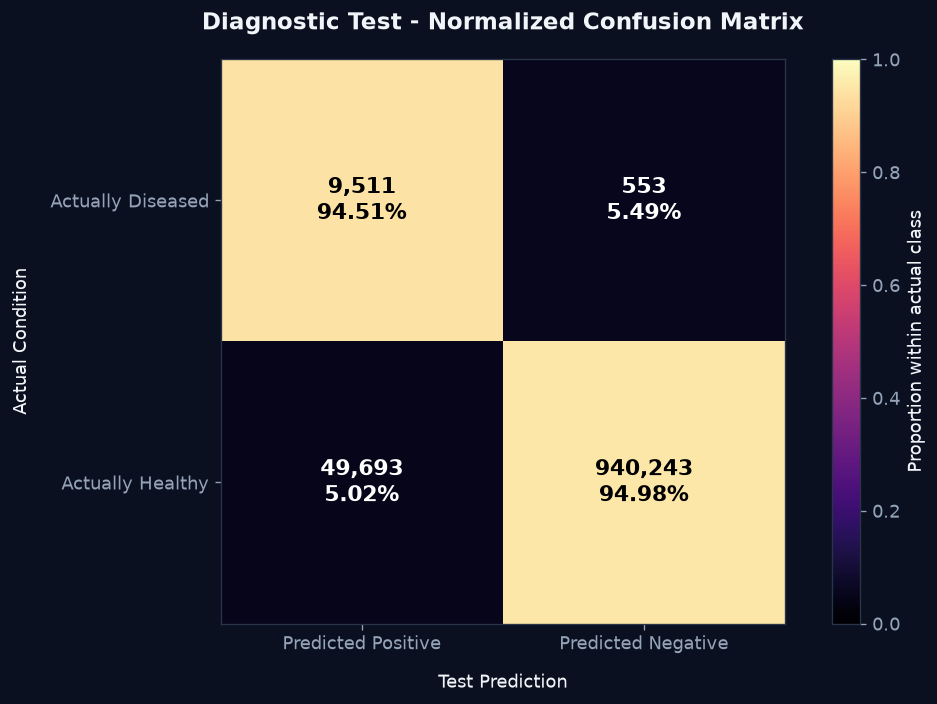

In [11]:
from matplotlib.ticker import PercentFormatter

confusion_matrix = np.array([
    [true_positives_sim, false_negatives_sim],
    [false_positives_sim, true_negatives_sim]
])

row_normalized = confusion_matrix / confusion_matrix.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    row_normalized,
    cmap="magma",
    vmin=0,
    vmax=1
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Predicted Positive", "Predicted Negative"])
ax.set_yticklabels(["Actually Diseased", "Actually Healthy"])

ax.set_title(
    "Diagnostic Test - Normalized Confusion Matrix",
    pad=18,
    fontweight="bold"
)

for i in range(2):
    for j in range(2):
        count = confusion_matrix[i, j]
        percentage = row_normalized[i, j]

        ax.text(
            j, i,
            f"{count:,}\n{percentage:.2%}",
            ha="center",
            va="center",
            fontsize=13,
            color="white" if percentage < 0.65 else "black",
            fontweight="bold"
        )

ax.set_xlabel("Test Prediction", labelpad=12)
ax.set_ylabel("Actual Condition", labelpad=12)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Proportion within actual class")

plt.tight_layout()
plt.show()

### **Interpretation**

The normalized confusion matrix reveals two important characteristics of the diagnostic test:

1. Among individuals who actually have the disease, approximately 95% receive a positive result. This corresponds to the test's sensitivity.
2. Among individuals who are healthy, approximately 95% receive a negative result. This corresponds to the test's specificity.

However, the matrix also illustrates why sensitivity and specificity must not be confused with the probability of having a disease after receiving a positive result.
Sensitivity and specificity are calculated across actual disease-status groups. The posterior probability is calculated within the group of positive test results.This distinction is fundamental to understanding diagnostic evaluation and classification metrics in Machine Learning.
___

## **The Effect of Disease Prevalence on Posterior Probability**

**Calculate posterior probability across prevalence values**

In [12]:
prevalence_values = np.linspace(0.001, 0.50, 500)

posterior_values = (
    sensitivity * prevalence_values
) / (
    sensitivity * prevalence_values
    + (1 - specificity) * (1 - prevalence_values)
)

prevalence_df = pd.DataFrame({
    "Prevalence": prevalence_values,
    "Posterior Probability": posterior_values
})

prevalence_df.head()

,Prevalence,Posterior Probability
0,0.001,0.018664
1,0.002,0.036680
2,0.003,0.054080
3,0.004,0.070896
4,0.005,0.087156


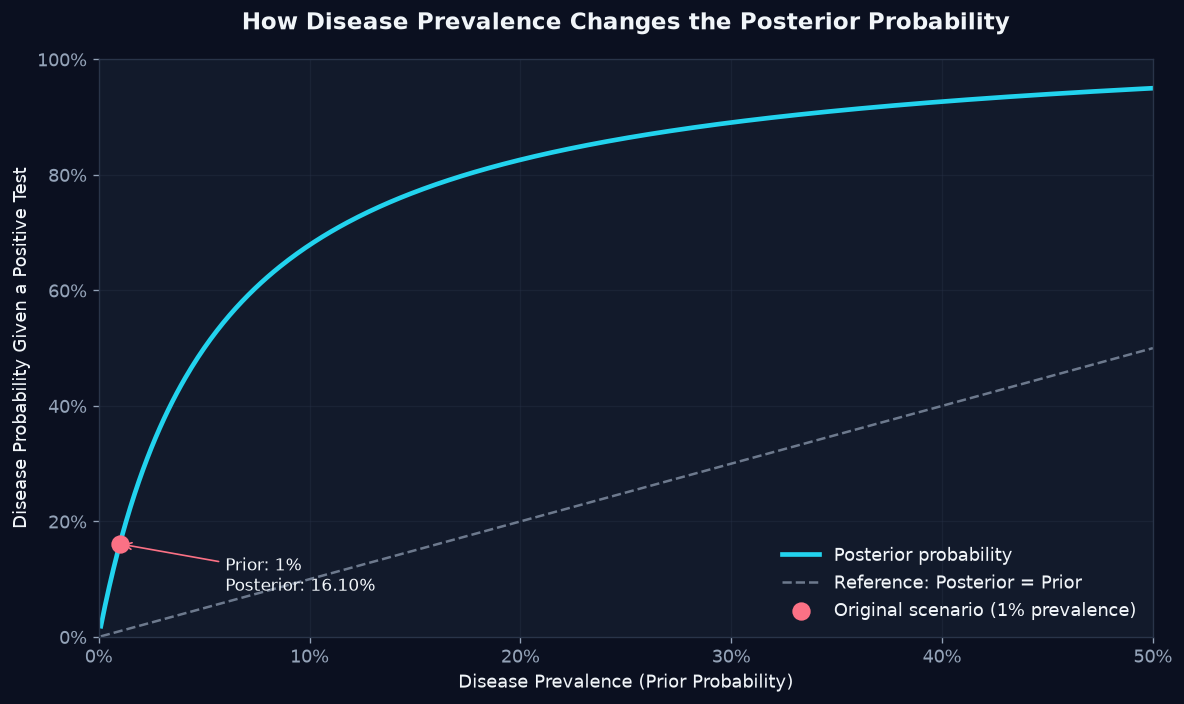

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    prevalence_values,
    posterior_values,
    linewidth=2.8,
    color=COLORS["cyan"],
    label="Posterior probability"
)

ax.plot(
    prevalence_values,
    prevalence_values,
    linestyle="--",
    linewidth=1.5,
    color=COLORS["muted"],
    alpha=0.7,
    label="Reference: Posterior = Prior"
)

ax.scatter(
    P_D,
    P_D_given_T,
    color=COLORS["coral"],
    s=100,
    zorder=5,
    label="Original scenario (1% prevalence)"
)

ax.annotate(
    f"Prior: {P_D:.0%}\nPosterior: {P_D_given_T:.2%}",
    xy=(P_D, P_D_given_T),
    xytext=(0.12, 0.08),
    textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": COLORS["coral"]},
    color=COLORS["text"],
    fontsize=10
)

ax.set_title(
    "How Disease Prevalence Changes the Posterior Probability",
    pad=18,
    fontweight="bold"
)

ax.set_xlabel("Disease Prevalence (Prior Probability)")
ax.set_ylabel("Disease Probability Given a Positive Test")

ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1)

ax.grid(alpha=0.35)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

### **Interpretation: Why prevalence matters**

The relationship demonstrates that the posterior probability increases as disease prevalence increases, assuming sensitivity and specificity remain fixed.
When the disease is rare, most individuals belong to the healthy population. Even a relatively small false positive rate can therefore produce a substantial number of false positive results.

As prevalence increases, the proportion of true positives among all positive results also increases.
The posterior probability can eventually become substantially higher than the prior probability.
This illustrates a central principle of Bayesian inference:

**The strength of evidence must be interpreted in the context of what was already known before the evidence appeared.**

A positive result from the same diagnostic test can therefore have very different implications for two populations with different disease prevalence.

___

## **Convergence of Monte Carlo estimation**

**Running posterior estimates**

In [14]:
rng = np.random.default_rng(42)

TOTAL_SAMPLES = 1_000_000
BATCH_SIZE = 10_000

running_true_positives = 0
running_positive_tests = 0

convergence_records = []

for start in range(0, TOTAL_SAMPLES, BATCH_SIZE):

    batch_size = min(
        BATCH_SIZE,
        TOTAL_SAMPLES - start
    )

    disease = rng.random(batch_size) < P_D

    positive = np.where(
        disease,
        rng.random(batch_size) < sensitivity,
        rng.random(batch_size) < (1 - specificity)
    )

    running_true_positives += np.sum(disease & positive)
    running_positive_tests += np.sum(positive)

    if running_positive_tests > 0:

        estimate = (
            running_true_positives / running_positive_tests
        )

        convergence_records.append({
            "Individuals Simulated": start + batch_size,
            "Positive Tests": running_positive_tests,
            "Posterior Estimate": estimate
        })

convergence_df = pd.DataFrame(convergence_records)

convergence_df.tail()

,Individuals Simulated,Positive Tests,Posterior Estimate
95,960000,56648,0.161294
96,970000,57239,0.161306
97,980000,57824,0.161179
98,990000,58445,0.161160
99,1000000,59055,0.161155


**Convergence Visualisation**

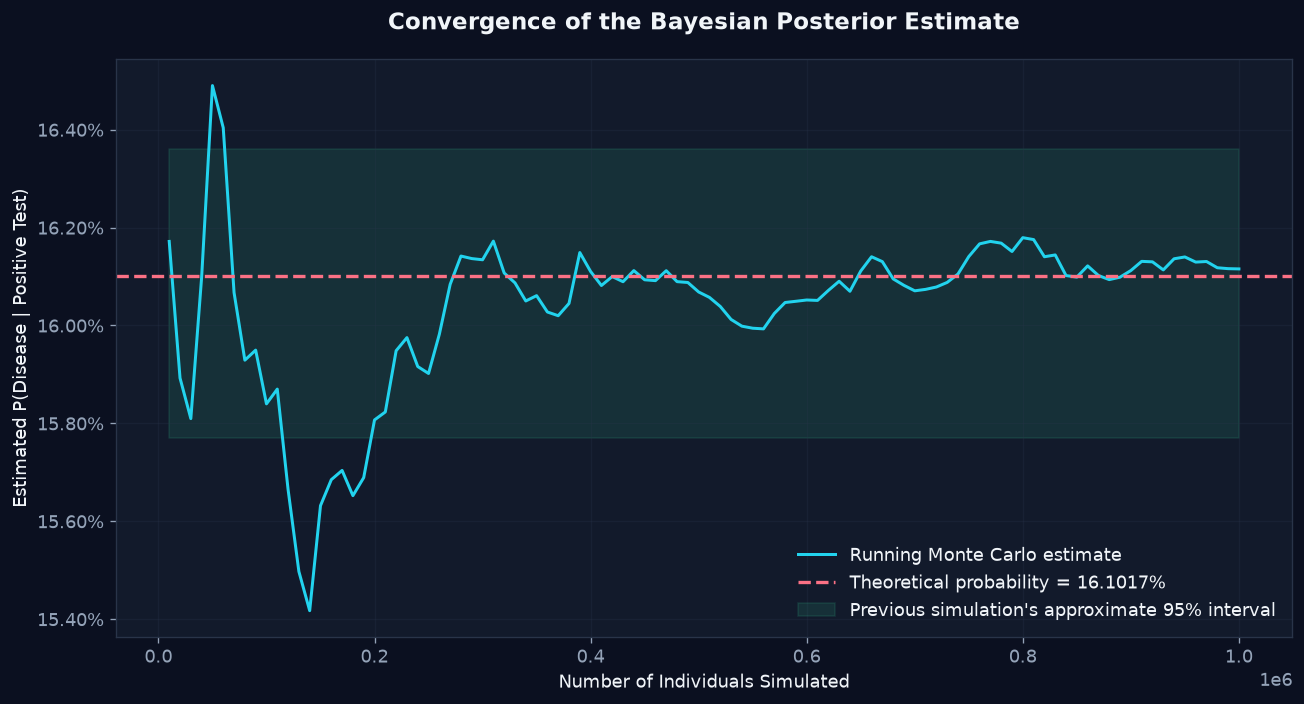

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    convergence_df["Individuals Simulated"],
    convergence_df["Posterior Estimate"],
    color=COLORS["cyan"],
    linewidth=1.8,
    label="Running Monte Carlo estimate"
)

ax.axhline(
    P_D_given_T,
    color=COLORS["coral"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical probability = {P_D_given_T:.4%}"
)

ax.fill_between(
    convergence_df["Individuals Simulated"],
    ci_lower,
    ci_upper,
    color=COLORS["green"],
    alpha=0.12,
    label="Previous simulation's approximate 95% interval"
)

ax.set_title(
    "Convergence of the Bayesian Posterior Estimate",
    pad=18,
    fontweight="bold"
)

ax.set_xlabel("Number of Individuals Simulated")
ax.set_ylabel("Estimated P(Disease | Positive Test)")

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.grid(alpha=0.3)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### **Interpretation**

The running estimate fluctuates as new individuals are added to the simulation.
Initially, relatively few positive test outcomes are available, so individual observations can have a noticeable effect on the estimated posterior probability.

As the sample size increases, the estimate generally becomes more stable and approaches the theoretical Bayesian probability.
This behaviour is consistent with the law of large numbers.
The convergence experiment demonstrates why Monte Carlo estimates become more reliable with larger sample sizes, although increasing the sample size does not eliminate every source of modelling error.

___

## **Connection to Machine Learning**

Bayesian reasoning is closely related to the evaluation of binary classification systems.

In Machine Learning:

$$
Precision=\frac{TP}{TP+FP}
$$

$$
Recall=\frac{TP}{TP+FN}
$$

For the diagnostic testing problem:

$$
Precision=P(D\mid T)
$$

$$
Recall=P(T\mid D)
$$

Thus, the posterior probability of disease given a positive test is equivalent to the positive predictive value, commonly represented by precision.
This connection is particularly important when working with imbalanced datasets.

For example, a fraud detection model may achieve 99% accuracy simply by predicting every transaction as legitimate when fraudulent transactions account for only 1% of the data.
Therefore, accuracy alone may provide a misleading assessment of model performance.

Precision, recall, specificity, and the underlying class distribution provide a more meaningful evaluation.

___

## **Key Findings**

1. A diagnostic test with 95% sensitivity and specificity does not necessarily imply a 95% probability of disease after a positive result.
2. The theoretical posterior probability in this problem is approximately 16.10%.
3. The low disease prevalence causes false positives to outnumber true positives.
4. Monte Carlo simulation independently reproduced the theoretical result with a small sampling error.
5. Posterior probability increases with disease prevalence when test characteristics remain fixed.
6. The interpretation of a positive prediction depends on both the predictive model and the underlying population distribution.

___
## **Limitations**

This experiment uses a simplified probabilistic model.

- Sensitivity and specificity are assumed to remain constant.
- Disease prevalence is treated as known.
- Test outcomes are assumed to follow the specified conditional probabilities.
- The model does not account for repeated testing, uncertain diagnoses, or changes in test performance across demographic groups.

Real-world medical decisions require additional clinical information and should not rely on this simplified model alone.

___
## **Conclusion**

The Disease Testing Problem demonstrates that probability is not merely about how frequently an event occurs. It is also about how new evidence changes our understanding of that event.
Bayes' theorem provides a formal mechanism for this update.

The most important lesson is that evidence cannot be interpreted independently of prior information. A positive test result may appear convincing, but its actual significance depends heavily on how common the underlying condition is.
This principle extends well beyond medical diagnosis. It is fundamental to statistical inference, classification systems, anomaly detection, fraud analysis, and many other applications of Data Science.

___

_Thanks for reading_

_by_

**Abdur Rahman (Rahven)**